# Task 3 — combined EDA with feature extraction

Repeat the raw quality and leakage checks, then add deterministic row-level spending and activity features. Feature families are motivated by [RFM in freemium games](https://scholar.smu.edu/datasciencereview/vol6/iss2/1/), [past transactions and interactions in gaming spending prediction](https://arxiv.org/abs/2409.17077), and [game playtime research](https://arxiv.org/abs/1912.06972). These sources motivate categories, not exact formulas or external data.

## 1. Load raw Train and Test

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from src.pipeline.random_seed import set_seed
from src.pipeline.save_data import save_data

SEED = set_seed()
RAW = SRC / "task3" / "data" / "raw"
ID, TARGET, DATA_NAME = "player_id", "spending_30d", "eda_combined_v1"
sns.set_theme(style="whitegrid")
train_raw = pd.read_csv(RAW / "train.csv")
test_raw = pd.read_csv(RAW / "test.csv")
display(pd.DataFrame({"rows": [len(train_raw), len(test_raw)],
                      "columns": [train_raw.shape[1], test_raw.shape[1]]},
                     index=["Train", "Test"]))

,rows,columns
Train,104000,34
Test,25889,33


## 2. Verify schema, IDs, and feature quality

In [2]:
assert train_raw.shape == (104000, 34) and test_raw.shape == (25889, 33)
assert TARGET in train_raw and TARGET not in test_raw
assert train_raw.drop(columns=TARGET).columns.tolist() == test_raw.columns.tolist()
assert train_raw[ID].notna().all() and test_raw[ID].notna().all()
assert train_raw[ID].is_unique and test_raw[ID].is_unique
assert not set(train_raw[ID]).intersection(test_raw[ID])
assert train_raw[TARGET].notna().all() and (train_raw[TARGET] >= 0).all()
feature_cols = test_raw.columns.drop(ID).tolist()
assert len(feature_cols) == 32
assert all(pd.api.types.is_numeric_dtype(train_raw[c]) for c in feature_cols)
assert not np.isinf(train_raw[feature_cols + [TARGET]].to_numpy()).any()
assert not np.isinf(test_raw[feature_cols].to_numpy()).any()
assert not train_raw.duplicated().any() and not test_raw.duplicated().any()
print("Features:", len(feature_cols), "| target missing:", train_raw[TARGET].isna().sum())
print("Duplicate/overlapping IDs:", train_raw[ID].duplicated().sum(),
      test_raw[ID].duplicated().sum(), len(set(train_raw[ID]) & set(test_raw[ID])))
display(pd.DataFrame({"train_dtype": train_raw.dtypes.astype(str),
                      "test_dtype": test_raw.dtypes.astype(str)}))

Features: 32 | target missing: 0
Duplicate/overlapping IDs: 0 0 0


,train_dtype,test_dtype
account_age_days,float64,float64
achievement_completion_rate,float64,float64
achievement_count,float64,float64
avg_session_length,float64,float64
avg_transaction_value,float64,float64
competitive_rank,float64,float64
cross_game_activity,float64,float64
daily_login_streak,float64,float64
days_since_last_login,float64,float64
days_since_last_purchase,float64,float64


,train_pct,test_pct
vip_status,5.95,5.69
achievement_count,5.95,5.82
cross_game_activity,5.92,5.93
days_since_last_purchase,5.91,5.78
sessions_per_week,5.90,5.93
platform,5.89,5.81
daily_login_streak,5.87,5.91
discount_rate_used,5.87,5.99
achievement_completion_rate,5.85,5.94
friend_count,5.85,5.98


Constant Train features: []
All-missing feature rows: 0 0


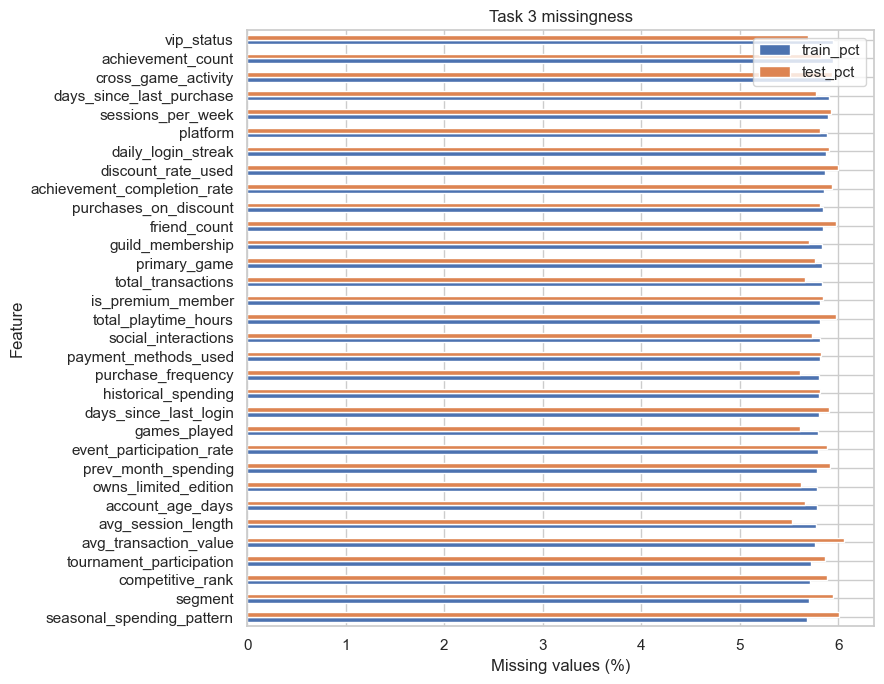

In [3]:
missing = pd.DataFrame({
    "train_pct": train_raw[feature_cols].isna().mean().mul(100),
    "test_pct": test_raw[feature_cols].isna().mean().mul(100),
}).sort_values("train_pct", ascending=False)
display(missing.round(2))
print("Constant Train features:", [c for c in feature_cols
                                   if train_raw[c].nunique(dropna=True) <= 1])
print("All-missing feature rows:", train_raw[feature_cols].isna().all(axis=1).sum(),
      test_raw[feature_cols].isna().all(axis=1).sum())
fig, ax = plt.subplots(figsize=(9, 7))
missing.sort_values("train_pct")[["train_pct", "test_pct"]].plot.barh(ax=ax)
ax.set(title="Task 3 missingness", xlabel="Missing values (%)", ylabel="Feature")
plt.tight_layout()
plt.show()

## 3. Inspect spending and predictors

,spending_30d
count,104000.000000
mean,10497.040585
std,30568.961446
min,0.000000
1%,0.000000
10%,0.000000
50%,79.435000
90%,37718.851000
95%,75969.751000
99%,150032.295400


Zero spenders: 50049 (48.1%)


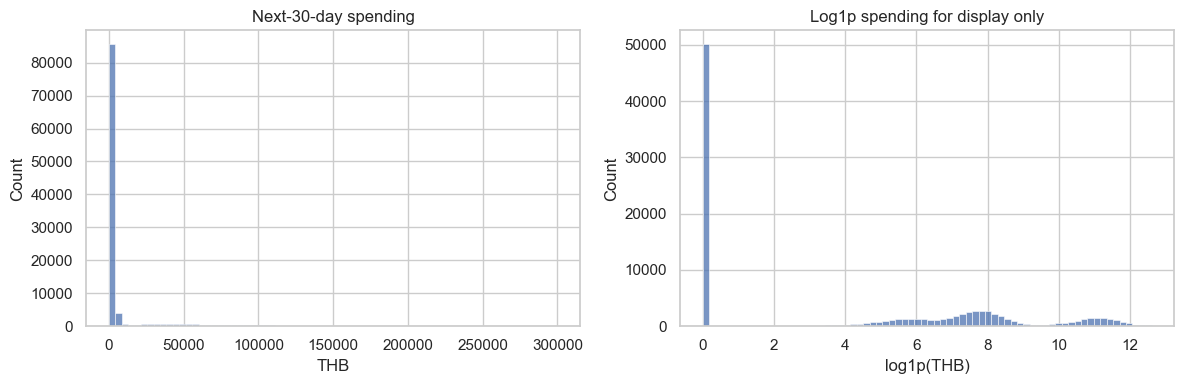

,count,mean,std,min,1%,50%,99%,max
friend_count,97917.0,110.41,65.39,0.00,2.00,106.00,275.00,410.00
social_interactions,97956.0,65.75,37.82,0.00,1.00,64.00,160.00,230.00
guild_membership,97928.0,0.60,0.49,0.00,0.00,1.00,1.00,1.00
event_participation_rate,97971.0,39.65,18.50,10.00,10.62,36.24,82.71,85.00
daily_login_streak,97893.0,56.57,35.72,0.00,1.00,53.00,149.00,256.00
avg_session_length,97997.0,110.24,54.75,20.00,21.91,105.90,250.41,364.43
sessions_per_week,97869.0,14.26,7.59,1.00,1.34,13.87,33.17,47.80
total_playtime_hours,97954.0,594.56,292.90,50.01,66.98,583.25,1312.51,1980.98
days_since_last_login,97965.0,7.35,5.45,0.00,0.12,6.25,23.09,40.91
achievement_count,97812.0,161.20,81.01,0.00,5.00,159.00,357.00,507.00


segment


,rows,zero_share,median,mean
segment,,,,
0.0,39241,0.724,0.00,73.958
1.0,24483,0.480,264.25,944.371
2.0,19762,0.306,1837.64,2283.845
3.0,14579,0.071,54760.28,65357.701
NaN,5935,0.468,125.56,11404.506


vip_status


,rows,zero_share,median,mean
vip_status,,,,
0.0,45803,0.599,0.000,1864.942
1.0,22812,0.502,0.000,5537.412
2.0,14664,0.405,860.585,15166.563
3.0,8802,0.181,4287.160,32310.777
4.0,3893,0.128,17473.860,47318.834
5.0,1837,0.076,55888.580,67318.635
NaN,6189,0.481,101.110,10546.836


is_premium_member


... (3 outputs left out)

prev_month_spending Spearman: 0.652
historical_spending Spearman: 0.6513
purchase_frequency Spearman: 0.1757


days_since_last_purchase

 Spearman: -0.2207


sessions_per_week Spearman: 0.1377


In [4]:
display(train_raw[TARGET].describe(percentiles=[.01, .1, .5, .9, .95, .99]).to_frame())
zero_count = int((train_raw[TARGET] == 0).sum())
print("Zero spenders:", zero_count, f"({zero_count / len(train_raw):.1%})")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_raw[TARGET], bins=70, ax=axes[0])
axes[0].set(title="Next-30-day spending", xlabel="THB")
sns.histplot(np.log1p(train_raw[TARGET]), bins=70, ax=axes[1])
axes[1].set(title="Log1p spending for display only", xlabel="log1p(THB)")
plt.tight_layout()
plt.show()
display(train_raw[feature_cols].describe(percentiles=[.01, .5, .99]).T.round(2))
for column in ["segment", "vip_status", "is_premium_member", "primary_game"]:
    print(column)
    display(train_raw.groupby(column, dropna=False)[TARGET].agg(
        rows="size", zero_share=lambda s: (s == 0).mean(),
        median="median", mean="mean").round(3))
for column in ["prev_month_spending", "historical_spending", "purchase_frequency",
               "days_since_last_purchase", "sessions_per_week"]:
    valid = train_raw[[column, TARGET]].dropna()
    print(column, "Spearman:", round(valid.corr(method="spearman").iloc[0, 1], 4))

## 4. Review leakage and metric definition

In [5]:
assert ID not in feature_cols and TARGET not in feature_cols
assert set(["prev_month_spending", "historical_spending", "segment"]) <= set(feature_cols)
print("Datacard calls spending inputs historical and segment a Task 2 classification.")
print("It does not provide feature timestamps. NMAE denominator is also absent.")
print("Model preprocessing will fit on development rows only.")

Datacard calls spending inputs historical and segment a Task 2 classification.
It does not provide feature timestamps. NMAE denominator is also absent.
Model preprocessing will fit on development rows only.


## 5. Extract row-level behavior features

RFM-style spending intensity, purchase recency, discount exposure, play intensity, and social activity can be formed from supplied columns. Fixed +1 denominators avoid division by zero. Missing source values remain missing; no label, ID, or learned statistic enters a formula.

In [6]:
def add_spending_features(df):
    out = df.copy()
    out["purchase_value_proxy"] = df["purchase_frequency"] * df["avg_transaction_value"]
    out["recent_to_historical_spend"] = df["prev_month_spending"] / (df["historical_spending"] + 1)
    out["historical_spend_per_account_month"] = df["historical_spending"] / (df["account_age_days"] / 30 + 1)
    out["transactions_per_account_month"] = df["total_transactions"] / (df["account_age_days"] / 30 + 1)
    out["historical_spend_per_transaction"] = df["historical_spending"] / (df["total_transactions"] + 1)
    out["discount_purchase_share"] = df["purchases_on_discount"] / (df["total_transactions"] + 1)
    out["discount_value_interaction"] = df["prev_month_spending"] * df["discount_rate_used"]
    out["purchase_recency_over_age"] = df["days_since_last_purchase"] / (df["account_age_days"] + 1)
    out["login_purchase_recency_gap"] = df["days_since_last_purchase"] - df["days_since_last_login"]
    out["session_hours_proxy_per_week"] = df["sessions_per_week"] * df["avg_session_length"] / 60
    out["play_hours_per_account_day"] = df["total_playtime_hours"] / (df["account_age_days"] + 1)
    out["social_interactions_per_session"] = df["social_interactions"] / (df["sessions_per_week"] + 1)
    out["cross_game_activity_per_session"] = df["cross_game_activity"] / (df["sessions_per_week"] + 1)
    out["achievements_per_play_hour"] = df["achievement_count"] / (df["total_playtime_hours"] + 1)
    out["event_social_interaction"] = df["event_participation_rate"] / 100 * df["social_interactions"]
    out["source_missing_count"] = df[feature_cols].isna().sum(axis=1)
    return out

train_combined = add_spending_features(train_raw)
test_combined = add_spending_features(test_raw)
engineered_cols = [c for c in test_combined if c not in test_raw]
assert len(engineered_cols) == 16
assert train_combined.drop(columns=TARGET).columns.tolist() == test_combined.columns.tolist()
assert train_combined[feature_cols + [ID, TARGET]].equals(train_raw[feature_cols + [ID, TARGET]])
assert test_combined[feature_cols + [ID]].equals(test_raw[feature_cols + [ID]])
assert not np.isinf(train_combined[engineered_cols].to_numpy()).any()
assert not np.isinf(test_combined[engineered_cols].to_numpy()).any()
print("Rows:", len(train_combined), len(test_combined), "| features:", len(feature_cols), "+", len(engineered_cols))
display(pd.DataFrame({
    "train_missing_pct": train_combined[engineered_cols].isna().mean().mul(100),
    "test_missing_pct": test_combined[engineered_cols].isna().mean().mul(100),
}).round(2))
spend_band = pd.cut(train_combined[TARGET],
                    bins=[-1, 0, 1000, 10000, np.inf],
                    labels=["zero", "low", "mid", "high"])
display(train_combined.groupby(spend_band, observed=True)[engineered_cols].median().round(2))

Rows: 104000 25889 | features: 32 + 16


,train_missing_pct,test_missing_pct
purchase_value_proxy,11.23,11.32
recent_to_historical_spend,11.23,11.41
historical_spend_per_account_month,11.28,11.17
transactions_per_account_month,11.28,10.94
historical_spend_per_transaction,11.30,11.12
discount_purchase_share,11.37,11.14
discount_value_interaction,11.35,11.57
purchase_recency_over_age,11.35,11.12
login_purchase_recency_gap,11.35,11.36
session_hours_proxy_per_week,11.32,11.20


,purchase_value_proxy,recent_to_historical_spend,historical_spend_per_account_month,transactions_per_account_month,historical_spend_per_transaction,discount_purchase_share,discount_value_interaction,purchase_recency_over_age,login_purchase_recency_gap,session_hours_proxy_per_week,play_hours_per_account_day,social_interactions_per_session,cross_game_activity_per_session,achievements_per_play_hour,event_social_interaction,source_missing_count
spending_30d,,,,,,,,,,,,,,,,
zero,258.31,0.35,47.87,1.63,30.99,0.35,105.94,0.06,27.38,18.80,0.91,4.21,0.98,0.27,15.71,2.0
low,185.05,0.35,32.07,1.53,20.08,0.35,74.85,0.05,21.73,17.69,0.89,4.20,0.98,0.27,14.08,2.0
mid,895.95,0.35,169.38,1.92,85.84,0.36,415.38,0.04,18.55,24.99,1.06,4.36,0.86,0.28,31.20,2.0
high,6597.68,0.35,1801.62,2.88,606.44,0.38,4655.04,0.04,14.71,30.54,1.14,4.43,0.79,0.27,50.66,2.0


## 6. Save combined dataset

The saved card links to the original raw files and lists all 16 engineered columns.

In [7]:
card_path = SRC / "task3" / "data" / "eda" / f"{DATA_NAME}.json"
if card_path.exists():
    data_info = json.loads(card_path.read_text(encoding="utf-8"))
    assert data_info["name"] == DATA_NAME
    assert data_info["splits"]["train"]["columns"] == {c: str(t) for c, t in train_combined.dtypes.items()}
    assert data_info["splits"]["test"]["columns"] == {c: str(t) for c, t in test_combined.dtypes.items()}
    assert pd.read_parquet(SRC / data_info["splits"]["train"]["path"]).equals(train_combined)
    assert pd.read_parquet(SRC / data_info["splits"]["test"]["path"]).equals(test_combined)
    print("Loaded existing dataset:", DATA_NAME)
else:
    data_info = save_data(
        task=3, name=DATA_NAME, train=train_combined, test=test_combined,
        card={
            "source": "task3/data/raw/train.csv and test.csv",
            "parent_dataset": "eda_original_v1",
            "preparation": "32 raw features plus 16 deterministic row-level spending and activity features; no fitted preprocessing.",
            "engineered_features": engineered_cols,
            "leakage_review": "No target or ID in formulas; no fitted statistics. Historical cutoff and segment availability remain unverified.",
            "metric_note": "Competition NMAE denominator not supplied; Round 1 uses MAE_thb.",
        }, format="parquet")
    print("Saved dataset:", DATA_NAME)
print(data_info["splits"]["train"]["path"])
print(data_info["splits"]["test"]["path"])

Loaded existing dataset: eda_combined_v1
task3/data/eda/eda_combined_v1-train.parquet
task3/data/eda/eda_combined_v1-test.parquet


### Combined findings

- Added 16 deterministic spending, recency, activity, and interaction features to the 32 raw inputs.
- Raw columns and missingness remain intact. Round 1 compares original and combined on the same validation rows.
- Historical cutoff, segment availability, and the NMAE denominator remain undocumented.